# 04 Transfer learning: hund eller katt?
*Data Mining & Analytics – Samling 3, dag 1*

Pensum: Géron kap. 11, «Reusing Pretrained Layers» (s. 286–292).

Datasett: bilder av hunder og katter. Mappen `../Data/datasett-hundogkatt` må ligge på riktig plass fo å kunne kjøre

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4.5)
rng = np.random.default_rng(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.13.1


In [2]:
path = "../Data/datasett-hundogkatt/training_set/training_set"
BILDE_STR = (96, 96)

tren_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
    path, validation_split=0.2, subset="both", seed=42,
    image_size=BILDE_STR, batch_size=32, label_mode="binary")
print("Klasser:", tren_ds.class_names)        # ['cats', 'dogs'] -> 0 = katt, 1 = hund

tren_ds = tren_ds.take(125).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.take(32).cache().prefetch(tf.data.AUTOTUNE)

Found 8005 files belonging to 2 classes.
Using 6404 files for training.
Using 1601 files for validation.
Klasser: ['cats', 'dogs']


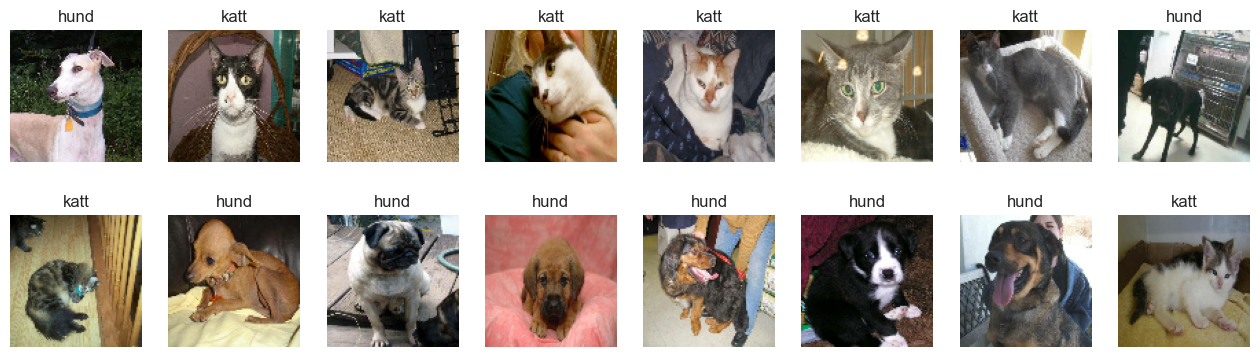

In [3]:
bilder, etiketter = next(iter(tren_ds))
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for i, a in enumerate(ax.ravel()):
    a.imshow(bilder[i].numpy().astype("uint8"))
    a.set_title("hund" if etiketter[i] == 1 else "katt"); a.axis("off")
plt.show()

## 1. Baseline: et lite CNN trent fra bunnen

In [4]:
auk = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomRotation(0.05)])

fra_bunnen = tf.keras.Sequential([
    tf.keras.Input(shape=BILDE_STR + (3,)),
    auk,
    tf.keras.layers.Rescaling(1 / 255),
    tf.keras.layers.Conv2D(32, 3, activation="relu"), tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, activation="relu"), tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(128, 3, activation="relu"), tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
fra_bunnen.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
h_bunn = fra_bunnen.fit(tren_ds, validation_data=val_ds, epochs=6, verbose=0)
print({k: round(v[-1], 3) for k, v in h_bunn.history.items() if k.startswith("val")})

{'val_loss': 0.641, 'val_accuracy': 0.646, 'val_auc': 0.704}


## 2. Transfer learning med MobileNetV2

Vi henter MobileNetV2 med vekter fra ImageNet, fjerner toppen (klassifiseringslaget for 1000 klasser) og **fryser**
alle lagene. Så legger vi til et nytt, lite «hode» for vårt binære problem. Bare hodet trenes.

In [ ]:
base = tf.keras.applications.MobileNetV2(input_shape=BILDE_STR + (3,), include_top=False, weights="imagenet")
base.trainable = False
print("Lag i basemodellen:", len(base.layers), " parametere:", f"{base.count_params():,}")

inn = tf.keras.Input(shape=BILDE_STR + (3,))
x = auk(inn)
x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)    # MobileNetV2 forventer verdier i [-1, 1]
x = base(x, training=False)                                 # hold batch-normaliseringen i inferensmodus
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
ut = tf.keras.layers.Dense(1, activation="sigmoid")(x)
overfort = tf.keras.Model(inn, ut)

overfort.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                 metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
print("Trenbare parametere:", sum(int(np.prod(v.shape)) for v in overfort.trainable_variables))
h_tl = overfort.fit(tren_ds, validation_data=val_ds, epochs=3, verbose=0)
print({k: round(v[-1], 3) for k, v in h_tl.history.items() if k.startswith("val")})

9406464/9406464 [==============================] - 1s 0us/step
Lag i basemodellen: 154  parametere: 2,257,984
Trenbare parametere: 1281


## 3. Finjustering (fine-tuning)

Når hodet er trent, kan vi «tine» de øverste lagene i basemodellen og trene videre med **svært lav læringsrate**,
slik at de forhåndstrente vektene bare justeres litt (Géron s. 290).

In [ ]:
base.trainable = True
for lag in base.layers[:-20]:          # frys alt unntatt de 20 øverste lagene
    lag.trainable = False

overfort.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="binary_crossentropy",
                 metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
h_fin = overfort.fit(tren_ds, validation_data=val_ds, epochs=2, verbose=0)
print({k: round(v[-1], 3) for k, v in h_fin.history.items() if k.startswith("val")})

In [ ]:
oversikt = pd.DataFrame({
    "CNN fra bunnen (6 epoker)": {k: h_bunn.history[k][-1] for k in ["val_accuracy", "val_auc"]},
    "Transfer learning (3 epoker)": {k: h_tl.history[k][-1] for k in ["val_accuracy", "val_auc"]},
    "+ finjustering (2 epoker)": {k: h_fin.history[k][-1] for k in ["val_accuracy", "val_auc"]},
}).T.round(3)
oversikt